<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (3000, 12)
Credit_Score
Standard    1350
Poor         900
Good         750
Name: count, dtype: int64 

Logistic Regression Accuracy: 0.8183
Random Forest Accuracy      : 0.76 

              precision    recall  f1-score   support

        Good       0.86      0.63      0.73       150
        Poor       0.89      0.68      0.77       180
    Standard       0.68      0.89      0.77       270

    accuracy                           0.76       600
   macro avg       0.81      0.73      0.75       600
weighted avg       0.79      0.76      0.76       600



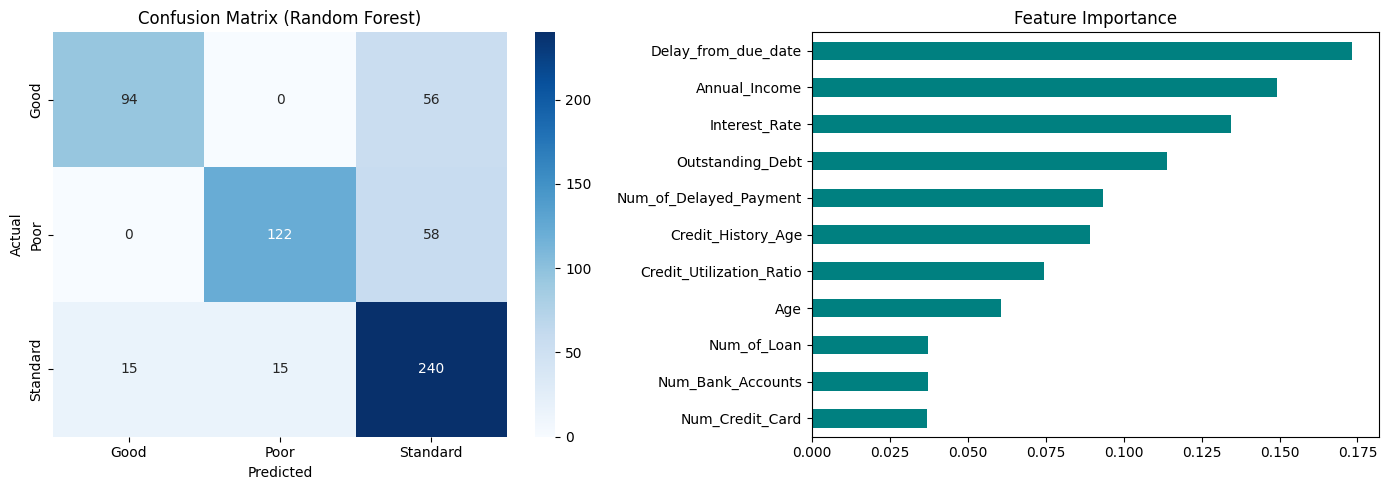

Predicted Credit Score: Good


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Create dataset (replace with pd.read_csv("train.csv") for the Kaggle dataset)
np.random.seed(42)
n = 3000
df = pd.DataFrame({
    "Age": np.random.randint(18, 70, n),
    "Annual_Income": np.random.normal(50000, 20000, n).clip(10000),
    "Num_Bank_Accounts": np.random.randint(1, 10, n),
    "Num_Credit_Card": np.random.randint(1, 10, n),
    "Interest_Rate": np.random.randint(2, 35, n),
    "Num_of_Loan": np.random.randint(0, 9, n),
    "Delay_from_due_date": np.random.randint(0, 60, n),
    "Num_of_Delayed_Payment": np.random.randint(0, 25, n),
    "Outstanding_Debt": np.random.uniform(0, 5000, n),
    "Credit_Utilization_Ratio": np.random.uniform(20, 50, n),
    "Credit_History_Age": np.random.randint(1, 35, n),
})

# Credit score is driven by these features plus noise
score = (0.00004 * df["Annual_Income"] - 0.08 * df["Interest_Rate"]
         - 0.05 * df["Delay_from_due_date"] - 0.08 * df["Num_of_Delayed_Payment"]
         - 0.0004 * df["Outstanding_Debt"] - 0.03 * df["Credit_Utilization_Ratio"]
         + 0.05 * df["Credit_History_Age"] + np.random.normal(0, 0.6, n))
df["Credit_Score"] = pd.qcut(score, [0, 0.3, 0.75, 1], labels=["Poor", "Standard", "Good"])

print("Dataset shape:", df.shape)
print(df["Credit_Score"].value_counts(), "\n")

# 2. Preprocessing
X = df.drop("Credit_Score", axis=1)
le = LabelEncoder()
y = le.fit_transform(df["Credit_Score"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_s, X_test_s = scaler.fit_transform(X_train), scaler.transform(X_test)

# 3. Train models
lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)

# 4. Evaluate
print("Logistic Regression Accuracy:", round(accuracy_score(y_test, lr.predict(X_test_s)), 4))
rf_pred = rf.predict(X_test)
print("Random Forest Accuracy      :", round(accuracy_score(y_test, rf_pred), 4), "\n")
print(classification_report(y_test, rf_pred, target_names=le.classes_))

# 5. Graphs
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[0])
ax[0].set_title("Confusion Matrix (Random Forest)")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=ax[1], color="teal")
ax[1].set_title("Feature Importance")
plt.tight_layout()
plt.show()

# 6. Predict a new customer
new = pd.DataFrame([[35, 60000, 4, 3, 8, 1, 3, 2, 500, 30, 12]], columns=X.columns)
print("Predicted Credit Score:", le.inverse_transform(rf.predict(new))[0])